# Metal demand against allocated supply

Three cubes read side by side — `build/metal_demand/metal_demand.nc`,
`build/non_energy_demand/non_energy_demand.nc` and
`build/allocation/final_supply_scaled.nc` — plus the two tables
`rules/compare.smk` derives from them.

Four figures: **0** every metal's demand and supply per scenario, in kt (**0b**
the energy system's demand alone, without other-sector demand or supply), **1**
every metal on one axis, **2** the scenario × metal trade matrix on energy-system
demand (**2b** on total demand, in the same column order), **3** every metal
placed against allocated supply. The working set they were chosen from is in
`supply_and_demand_archive.ipynb`.

Run by the `visualise_supply_and_demand` rule, or interactively (paths then
resolve relative to the repo root).

In [1]:
import sys
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml

# Neither snakemake nor an interactive session puts scripts/ on the path.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting
from utils import get_mineral_groups
from info_schemas import (
    SCENARIO_SEPARATOR,
    MAX_REDUCTION_SCENARIO,
    ScenarioEffect,
    MaxReduction,
    MetalPosition,
    MineralInfo,
)

try:
    paths = {
        "demand": snakemake.input.demand,  # type: ignore
        "non_energy_demand": snakemake.input.non_energy_demand,  # type: ignore
        "supply": snakemake.input.supply,  # type: ignore
        "mineral_info": snakemake.input.mineral_info,  # type: ignore
        "positions": snakemake.input.positions,  # type: ignore
        "scenario_effects": snakemake.input.scenario_effects,  # type: ignore
        "max_reduction": snakemake.input.max_reduction,  # type: ignore
        "max_reduction_demand": snakemake.input.max_reduction_demand,  # type: ignore
        "figures": snakemake.output.figures,  # type: ignore
    }
    technology_info = dict(snakemake.params.technology_info)  # type: ignore
    scenario_info = dict(snakemake.params.scenario_info)  # type: ignore
    scenario_groups = dict(snakemake.params.scenario_groups)  # type: ignore
    mineral_groups = dict(snakemake.params.mineral_groups)  # type: ignore
    base_scenario = snakemake.params.base_scenario  # type: ignore
    reference_method = snakemake.params.reference_method  # type: ignore
    allocation_style = dict(snakemake.params.allocation_style)  # type: ignore
    non_energy_style = dict(snakemake.params.non_energy_style)  # type: ignore
    share_axis = dict(snakemake.params.share_axis)  # type: ignore
    window = dict(snakemake.params.window)  # type: ignore
    metal_types = dict(snakemake.params.metal_types)  # type: ignore
    metal_type_classes = dict(snakemake.params.metal_type_classes)  # type: ignore
    positions_style = dict(snakemake.params.positions_style)  # type: ignore
    row_sort = snakemake.params.row_sort  # type: ignore
    scenario_effects_style = dict(snakemake.params.scenario_effects_style)  # type: ignore
    max_reduction_style = dict(snakemake.params.max_reduction_style)  # type: ignore
    excluded_metals = list(snakemake.params.excluded_metals)  # type: ignore
    style = dict(snakemake.params.plotting)  # type: ignore
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    technology_info = config["technology_info"]
    scenario_info = config["scenarios"]
    scenario_groups = config["scenario_groups"]
    mineral_groups = get_mineral_groups(config, repo / "data/mineral_info.csv")
    base_scenario = config["compare"]["base_scenario"]
    reference_method = config["compare"]["reference_method"]
    allocation_style = config["compare"]["allocation_style"]
    non_energy_style = config["compare"]["non_energy"]
    share_axis = config["compare"]["share_axis"]
    window = config["window"]
    metal_types = config["compare"]["metal_types"]
    metal_type_classes = config["compare"]["metal_type_classes"]
    positions_style = config["compare"]["positions"]
    row_sort = config["compare"]["floor"]["sort_by"]
    scenario_effects_style = config["compare"]["scenario_effects"]
    max_reduction_style = config["compare"]["max_reduction"]
    excluded_metals = config["compare"]["excluded_metals"]
    style = config["plotting"]
    paths = {
        "demand": repo / "build/metal_demand/metal_demand.nc",
        "non_energy_demand": repo / "build/non_energy_demand/non_energy_demand.nc",
        "supply": repo / "build/allocation/final_supply_scaled.nc",
        "mineral_info": repo / "data/mineral_info.csv",
        "positions": repo / "build/compare/metal_positions.csv",
        "scenario_effects": repo / "build/compare/scenario_effects.csv",
        "max_reduction": repo / "build/compare/max_reduction.csv",
        "max_reduction_demand": repo / "build/compare/max_reduction.nc",
        "figures": repo / "build/compare/figures",
    }

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)

# Machine key -> display name / colour, in config order (which sets stack order).
technology_nice = {t: info["nice_name"] for t, info in technology_info.items()}
technology_color = {t: info["color"] for t, info in technology_info.items()}
scenario_nice = {s: info["nice_name"] for s, info in scenario_info.items()}
group_nice = {g: info["nice_name"] for g, info in mineral_groups.items()}
group_color = {g: info["color"] for g, info in mineral_groups.items()}

In [2]:
demand = xr.open_dataset(paths["demand"])["metal_demand_kt"]
supply = xr.open_dataset(paths["supply"])
non_energy = xr.open_dataset(paths["non_energy_demand"])

allocated_supply = supply["allocated_supply"]
other_sector_demand = non_energy["total_non_energy_demand"]
total_supply = supply["total_supply"]


def hold_out(cube):
    """Drop the metals the config says do not line up yet."""
    return cube.drop_sel(metal=sorted(set(cube["metal"].values) & set(excluded_metals)))


# A metal on one side only would draw a bar against no ceiling, or a ceiling
# against no bar, and either reads as a finding rather than as missing data.
cubes = {
    "demand": demand,
    "non-energy demand": other_sector_demand,
    "supply": allocated_supply,
}
stale = set(excluded_metals) - set().union(*(set(c["metal"].values) for c in cubes.values()))
if stale:
    raise ValueError(
        f"compare.excluded_metals holds out metals no cube carries: {sorted(stale)}"
    )

demand, other_sector_demand, allocated_supply = map(hold_out, cubes.values())
total_supply = hold_out(total_supply)

covered = {name: frozenset(hold_out(c)["metal"].values) for name, c in cubes.items()}
if len(set(covered.values())) != 1:
    everywhere = frozenset.intersection(*covered.values())
    raise ValueError(
        "the cubes do not cover the same metals. Either fix the source or hold "
        "these out in compare.excluded_metals: "
        + str({name: sorted(m - everywhere) for name, m in covered.items() if m - everywhere})
    )

# Principles strictest first: the order the lines rise in, a property of the
# shares rather than of how the config lists them.
shares = supply["study_share"].to_pandas()
if set(shares.index) != set(allocation_style):
    raise ValueError(
        f"compare.allocation_style styles {sorted(allocation_style)}, but the "
        f"supply cube carries {sorted(shares.index)}"
    )
# Supply is allocated three ways; other-sector demand is not (rules/ned.smk
# measures its share per metal), which is why the figures draw one grey band.
if "allocation_method" in non_energy.dims:
    raise ValueError(
        "the non-energy demand cube still varies by allocation principle, but the "
        "figures below draw one other-sector band and would hide the other two"
    )
methods = list(shares.sort_values().index)
method_nice = {m: str(supply["source_label"].sel(allocation_method=m).values) for m in methods}
# What a figure calls a principle when there is no room for the published name.
method_short = {m: allocation_style[m]["nice_name"] for m in methods}

# The one principle the ratio figures divide by; the others are parity lines.
if reference_method not in methods:
    raise ValueError(
        f"compare.reference_method is {reference_method!r}, but the supply cube "
        f"carries {sorted(methods)}"
    )

scenarios = [s for s in scenario_info if s in set(demand["scenario"].values)]
unconfigured = set(demand["scenario"].values) - set(scenarios)
if unconfigured:
    raise ValueError(f"cube scenarios missing from config `scenarios`: {sorted(unconfigured)}")
reference = base_scenario
if reference not in scenarios:
    raise ValueError(
        f"compare.base_scenario is {reference!r}, but the demand cube carries "
        f"{sorted(scenarios)}"
    )

print(f"{len(demand['metal'])} metals x {len(scenarios)} scenarios x {len(methods)} principles")
print(f"held out: {sorted(excluded_metals)}; reference scenario: {reference!r}")
for method in methods:
    marker = "  <- ratios are against this" if method == reference_method else ""
    print(f"  {method_nice[method]:>38}: {shares[method]:.1%} of world supply{marker}")

24 metals x 13 scenarios x 3 principles
held out: []; reference scenario: 'base'
     Per capita corrected for energy use: 4.1% of world supply
                        Per capita share: 6.9% of world supply
                               GDP share: 17.9% of world supply  <- ratios are against this


In [3]:
mineral_info = pd.read_csv(paths["mineral_info"]).set_index(MineralInfo.mineral)

unknown = set(demand["metal"].values) - set(mineral_info.index)
if unknown:
    raise KeyError(f"cube metals with no row in mineral_info.csv: {sorted(unknown)}")

# Metals and end-use groups in the order mineral_info.csv lists them, which is
# the order Fig. 1 blocks its bars in.
metals = [m for m in mineral_info.index if m in set(demand["metal"].values)]
grouped = {}
for metal in metals:
    grouped.setdefault(mineral_info.loc[metal, MineralInfo.group], []).append(metal)

# The supply-side character, in the two classes of compare.metal_type_classes
# rather than the four readings behind them: one distinction, drawn the same way
# on all three figures, is one a reader learns once. Every `type` value has to be
# claimed by exactly one reading and every reading filed under a declared class,
# or a metal would carry no character (or two).
type_class = {}
for name, spec in metal_types.items():
    if spec["class"] not in metal_type_classes:
        raise ValueError(
            f"compare.metal_types puts {name} in class {spec['class']!r}, which "
            "compare.metal_type_classes does not declare"
        )
    for value in spec["types"]:
        if value in type_class:
            raise ValueError(f"metal type {value!r} claimed by {type_class[value]} and {name}")
        type_class[value] = spec["class"]
unclaimed = {mineral_info.loc[m, MineralInfo.type] for m in metals} - set(type_class)
if unclaimed:
    raise ValueError(f"compare.metal_types claims no class for: {sorted(unclaimed)}")
metal_class = {m: type_class[mineral_info.loc[m, MineralInfo.type]] for m in metals}

# All three figures say it the same way: in how the metal's name is written. The
# weight and the slant are the encoding proper and travel to every one of them;
# the ink is only free where the panel is not already spending colour on
# something else, which is why it is held separately.
class_emphasis = {
    name: {"style": spec["label_style"], "weight": spec["label_weight"]}
    for name, spec in metal_type_classes.items()
}
class_label_style = {
    name: {**emphasis, "color": style["ink"][metal_type_classes[name]["label_ink"]]}
    for name, emphasis in class_emphasis.items()
}
# Figs. 1 and 2 spend no colour on their metal names, so those take the ink too;
# Fig. 3 colours a name by the metal's end use and takes the emphasis alone.
metal_label_style = {m: class_label_style[metal_class[m]] for m in metals}
metal_label_emphasis = {m: class_emphasis[metal_class[m]] for m in metals}

# Fig. 3 names each metal in full, bar the few in its most crowded corner.
abbreviated = positions_style["label"]["abbreviated"]
untracked = sorted(set(abbreviated) - set(metals))
if untracked:
    raise ValueError(f"compare.positions.label.abbreviated names untracked metals: {untracked}")
unnamed = [m for m in abbreviated if pd.isna(mineral_info.loc[m, MineralInfo.short_name])]
if unnamed:
    raise ValueError(f"mineral_info.csv gives no short_name for: {unnamed}")
position_name = {
    m: mineral_info.loc[m, MineralInfo.short_name] if m in abbreviated else m for m in metals
}
# The key entry for that encoding is set the way the names it describes are, so
# the entry is its own swatch. Figs. 1 and 2 give it no handle at all; Fig. 3
# hangs its dot on the same entry, since there the size says it too.
class_key = {spec["nice_name"]: name for name, spec in metal_type_classes.items()}

# Stack segments: config order, minus the technologies that never touch a metal
# in the comparison.
technologies = [
    t
    for t in technology_info
    if t in set(demand["technology"].values)
    and float(abs(demand.sel(technology=t)).sum()) > 0
]

NON_ENERGY_SEGMENT = "other_sectors"
non_energy_color = {NON_ENERGY_SEGMENT: non_energy_style["color"]}

for group, group_metals in grouped.items():
    print(f"{group_nice[group]:>20}: {', '.join(group_metals)}")
for name, spec in metal_type_classes.items():
    named = ", ".join(m for m in metals if metal_class[m] == name)
    print(f"{spec['nice_name']:>20}: {named}")

           Conductor: Aluminium, Copper
       Semiconductor: Cadmium, Gallium, Germanium, Indium, Selenium, Tellurium
             Battery: Cobalt, Graphite, Lithium
         Magnet REEs: Dysprosium, Neodymium, Praseodymium, Terbium
            Catalyst: Iridium, Platinum
            Dual-use: Manganese, Molybdenum, Nickel, Niobium, Silver, Tin, Vanadium
Primary / co-product: Aluminium, Copper, Dysprosium, Lithium, Manganese, Neodymium, Nickel, Niobium, Platinum, Praseodymium, Terbium, Tin
By-product / synthetic option: Cadmium, Cobalt, Gallium, Germanium, Graphite, Indium, Iridium, Molybdenum, Selenium, Silver, Tellurium, Vanadium


In [4]:
metal_positions = pd.read_csv(paths["positions"])

# Figs. 2 and 3 divide by one principle's supply; the other two contribute
# only their parity level, which is metal-independent.
placed = (
    metal_positions[
        metal_positions[MetalPosition.allocation_method] == reference_method
    ]
    .set_index(str(MetalPosition.metal))
    .reindex(metals)
)
if placed.isna().any(axis=None):
    absent = placed.index[placed.isna().any(axis=1)].tolist()
    raise ValueError(f"metal_positions.csv places no {reference_method} row for: {absent}")

traced_from = set(placed[MetalPosition.base_scenario])
if traced_from != {reference}:
    raise ValueError(
        f"metal_positions.csv traces from {sorted(traced_from)}, but the figures "
        f"read the reference scenario as {reference!r}"
    )

parity_rows = metal_positions.set_index(
    [str(MetalPosition.allocation_method), str(MetalPosition.metal)]
)


def parity_levels(column):
    """Each principle's parity on the axis `column` is drawn against.

    The level is metal-independent by construction, so any metal's row gives it;
    reading them all and checking they agree is what says so out loud.
    """
    levels = {}
    for method in methods:
        values = parity_rows.loc[method, column]
        if not np.allclose(values, values.iloc[0]):
            raise ValueError(
                f"{column} varies by metal under {method}; it is meant to be the "
                "share ratio alone, so the figure cannot draw it as one line"
            )
        levels[method] = float(values.iloc[0])
    return levels


# Whose problem each metal's shortfall is: the cluster build_metal_positions
# files it under, read off where the combined end of the trace lands against
# parity and, for a metal above it, off Fig. 3's x axis. No figure here colours
# by it, so only its names are taken; it is printed under Fig. 3.
cluster_style = positions_style["cluster"]
metal_cluster = placed[MetalPosition.cluster].to_dict()
unstyled = set(metal_cluster.values()) - set(cluster_style)
if unstyled:
    raise ValueError(
        f"metal_positions.csv files metals under {sorted(unstyled)}, which "
        "compare.positions.cluster does not style"
    )
cluster_nice = {name: spec["nice_name"] for name, spec in cluster_style.items()}
# Config order is the order the two cuts are applied in, and so the order the
# clusters are named in; only the ones something sits in, since naming an empty
# one claims the study covers more than it does.
occupied_clusters = [c for c in cluster_style if c in set(metal_cluster.values())]

ratio_parity = parity_levels(MetalPosition.parity_level_ratio)
print(f"metals placed against {method_nice[reference_method]}, whose parity is 1.00x")
for method in methods:
    print(f"  {method_nice[method]:>38}: parity at {ratio_parity[method]:.2f}x")

metals placed against GDP share, whose parity is 1.00x
     Per capita corrected for energy use: parity at 0.23x
                        Per capita share: parity at 0.39x
                               GDP share: parity at 1.00x


## Fig. 0

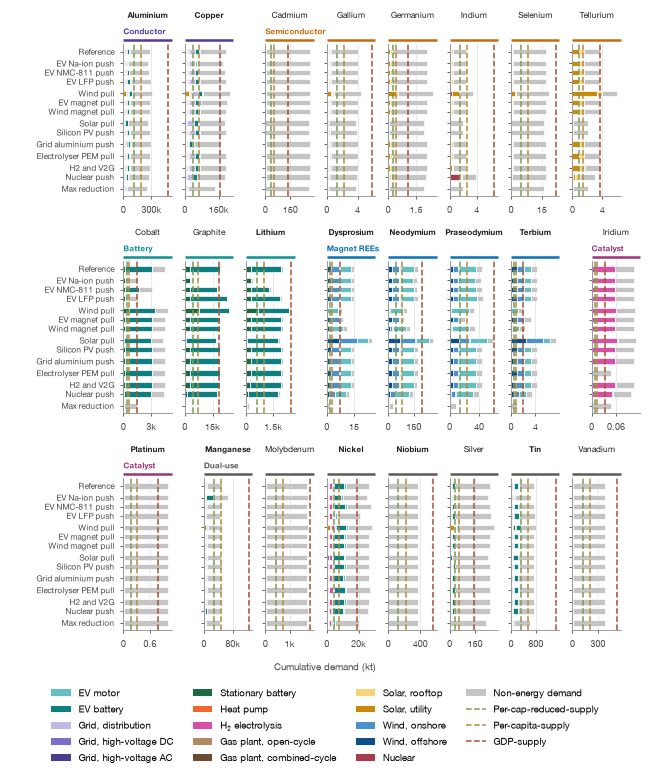

In [5]:
# The least energy-system demand a combination of scenarios leaves each metal
# with. Each metal takes its own combination, so it is an envelope over the scenario
# set rather than a world, and is joined on here rather than being a scenario.
max_reduction = hold_out(xr.open_dataset(paths["max_reduction_demand"])["metal_demand_kt"])
if MAX_REDUCTION_SCENARIO in scenarios:
    raise ValueError(
        f"{MAX_REDUCTION_SCENARIO!r} is both a config scenario and the label the "
        "max-reduction cube carries, so one bar would draw over the other"
    )
panel_demand = xr.concat([demand, max_reduction], dim="scenario")
bar_nice = {**scenario_nice, MAX_REDUCTION_SCENARIO: max_reduction_style["nice_name"]}

# Bars blocked by the question their scenarios ask, with the envelope as a block
# of its own at the end: it answers all of them at once.
scenario_members = plotting.grouped_members(
    scenarios, {s: info["group"] for s, info in scenario_info.items()}, scenario_groups
)
scenario_members[MAX_REDUCTION_SCENARIO] = [MAX_REDUCTION_SCENARIO]
bar_order = [s for members in scenario_members.values() for s in members]

kt_panel_key = "metal_panel"
# The figure's height is its scenario axis, so it takes the panel spec's own
# smaller gap between scenario groups.
bar_y = plotting.bar_positions(
    scenario_members, style, gap=style[kt_panel_key]["group_gap"]
)


def kt_panels(name, non_energy):
    """A panel per metal in kt, written to `name`. `non_energy=False` draws the
    energy system's demand alone: no other-sector band and no supply lines, since
    supply is read against the whole demand."""
    fig, axes, bands = plotting.flow_panel_grid(
        grouped, bar_y, bar_nice, group_color, group_nice, style,
        panel_key=kt_panel_key,
        value_label=(
            "Cumulative demand (kt)" if non_energy
            else "Cumulative energy-system demand (kt)"
        ),
    )

    for metal, ax in axes.items():
        energy = (
            panel_demand.sel(metal=metal)
            .to_series()
            .unstack("technology")
            .reindex(index=bar_order, columns=technologies)
        )
        top = plotting.stacked_bars(
            ax, bar_y, energy, technology_color, style,
            panel_key=kt_panel_key, orientation="horizontal",
        )
        if non_energy:
            # The same band on every bar: other-sector demand varies with no scenario.
            other_sectors = pd.DataFrame(
                {NON_ENERGY_SEGMENT: float(other_sector_demand.sel(metal=metal))},
                index=bar_order,
            )
            top = plotting.stacked_bars(
                ax, bar_y, other_sectors, non_energy_color, style,
                bottom=top, panel_key=kt_panel_key, orientation="horizontal",
            )
            granted = {
                method: float(allocated_supply.sel(metal=metal, allocation_method=method))
                for method in methods
            }
            plotting.reference_lines(
                ax, granted, allocation_style, "supply_color", "supply_linestyle",
                orientation="horizontal",
            )
        else:
            granted = {}
        # Every panel is on its own scale; the figure names the unit once.
        plotting.style_panel(
            ax, style, title=metal, ylabel="", orientation="horizontal",
            title_style={
                "fontsize": style[kt_panel_key]["title_size"], **metal_label_style[metal]
            },
            title_loc="center",
            extra_pad=plotting.band_title_pad(style, kt_panel_key),
        )
        # The row's own column of names carries the scenarios.
        plotting.category_axis(
            ax, bar_y, None, style, panel_key=kt_panel_key, orientation="horizontal"
        )
        ax.set_xlim(0, 1.08 * max([top.max(), *granted.values()]))
        plotting.compact_ticks(ax, style, kt_panel_key, "horizontal")

    handles = plotting.patch_handles(
        reversed(technologies), technology_color, technology_nice
    )
    if non_energy:
        handles += [
            *plotting.patch_handles(
                [NON_ENERGY_SEGMENT], non_energy_color,
                {NON_ENERGY_SEGMENT: non_energy_style["nice_name"]},
            ),
            *plotting.line_handles(
                methods, allocation_style,
                {method: f"{method_short[method]}-supply" for method in methods},
                "supply_color", "supply_linestyle",
            ),
        ]
    legend = fig.legend(
        handles=handles,
        frameon=False,
        ncol=4,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.0),
    )
    plotting.save_figure(fig, figures_dir, name, style, (legend, *bands))


kt_panels("demand_and_supply_kt", non_energy=True)

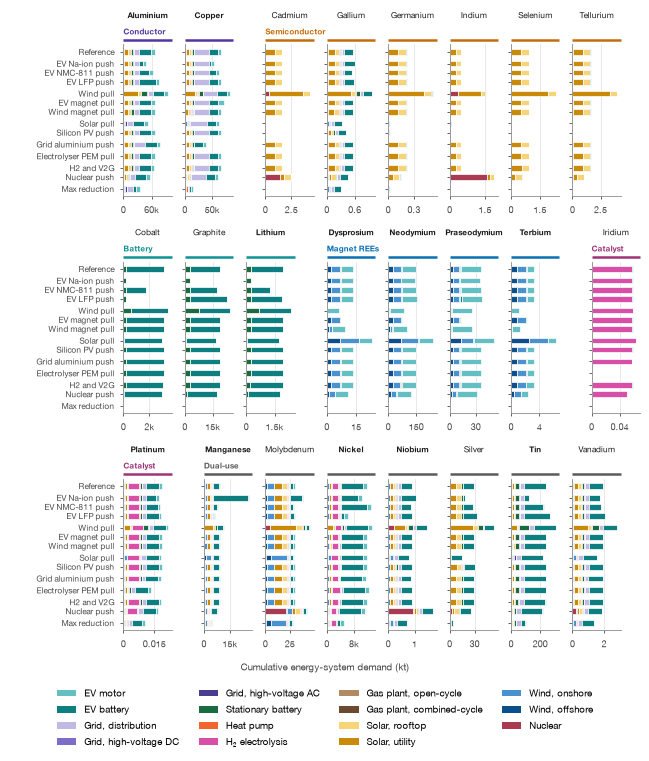

In [6]:
kt_panels("demand_and_supply_kt_energy_only", non_energy=False)

## Fig. 1

axis capped at 50%; bars cut: Cobalt, Iridium
other-sector band, high confidence: Aluminium, Cobalt, Copper, Gallium, Germanium, Graphite, Indium, Lithium, Manganese, Nickel, Niobium, Platinum, Vanadium
other-sector band, medium confidence: Dysprosium, Neodymium, Praseodymium, Terbium
other-sector band, low confidence: Cadmium, Iridium, Molybdenum, Selenium, Silver, Tellurium, Tin


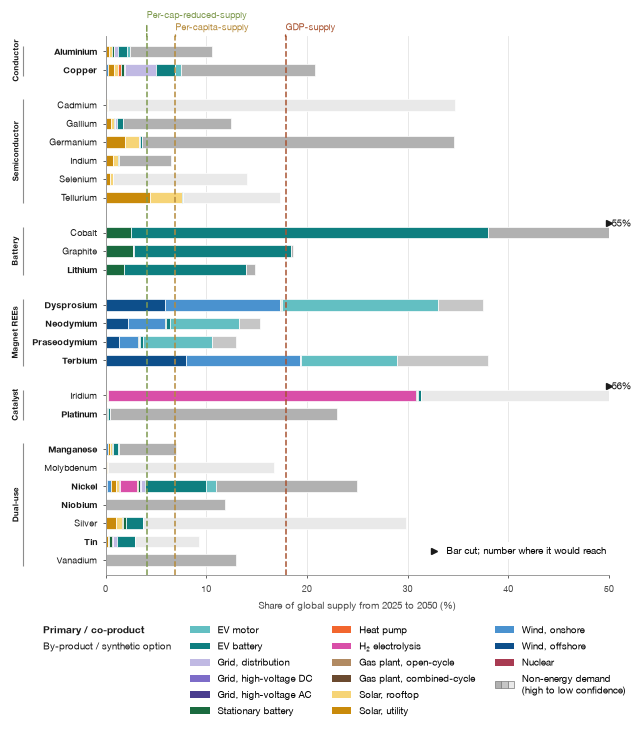

In [7]:
granted = {method: 100 * shares[method] for method in methods}
cap = share_axis["cap_percent"]
if cap <= max(granted.values()):
    raise ValueError(
        f"compare.share_axis.cap_percent is {cap}%, at or below the most generous "
        f"share ({max(granted.values()):.1f}%); its line would leave the axis"
    )

# Every quantity as a percentage of that metal's world supply over the window.
scale = total_supply.to_pandas().reindex(metals) / 100
energy = (
    demand.sel(scenario=reference)
    .to_series()
    .unstack("technology")
    .reindex(index=metals, columns=technologies)
    .div(scale, axis=0)
)
other_sectors = pd.DataFrame(
    {NON_ENERGY_SEGMENT: other_sector_demand.to_pandas().reindex(metals) / scale}
)

# How well the band's own height is known, written into how it is filled: the
# same grey throughout, weakening as the basis does.
confidence_style = non_energy_style["confidence"]
band_style = {
    level: {"facecolor": spec["color"], "hatch": spec["hatch"]}
    for level, spec in confidence_style.items()
}
# The key sits on no shared axis, so its swatch is outlined — without it the
# palest of the three greys has no boundary against the page.
band_key_style = {
    level: {
        **spec,
        "edgecolor": non_energy_style["edge_color"],
        "linewidth": style["bar"]["edge_width"],
    }
    for level, spec in band_style.items()
}
band_confidence = non_energy["confidence"].to_series().reindex(metals)
unstyled = sorted(set(band_confidence) - set(band_style))
if unstyled:
    raise ValueError(
        f"the non-energy cube carries confidence {unstyled}, which "
        "compare.non_energy.confidence gives no way to draw"
    )
# Only the levels the drawn metals use: three entries where the bars carry two
# would say the band means something it does not.
band_levels = [level for level in band_style if level in set(band_confidence)]
# One key entry, its shades running from the first level named to the last, and
# on two lines: at full length it would be the widest column of the key.
shades = [confidence_style[level]["nice_name"] for level in band_levels]
band_span = " to ".join(dict.fromkeys([shades[0], shades[-1]]))
band_label = f"{non_energy_style['nice_name']}\n({band_span} confidence)"
band_handle, band_handler = plotting.swatch_run(band_levels, band_key_style, band_label)

panel_key = "metal_axis_turned"
metal_y = plotting.bar_positions(grouped, style)
fig, ax = plt.subplots(
    figsize=plotting.turned_figure_size(metal_y, style, panel_key),
    layout="constrained",
)

top = plotting.stacked_bars(
    ax, metal_y, energy, technology_color, style,
    panel_key=panel_key, orientation="horizontal",
)
top = plotting.stacked_bars(
    ax, metal_y, other_sectors, non_energy_color, style,
    bottom=top, panel_key=panel_key, orientation="horizontal",
    row_styles={metal: band_style[level] for metal, level in band_confidence.items()},
)
# The cap is the axis, not a clip on the data: overrun_marks says of every bar
# it cuts that it is cut, and where it reaches. Set before the line names, which
# are packed against the value axis's own scale.
ax.set_xlim(0, cap)

line_names = plotting.reference_lines(
    ax, granted, allocation_style, "supply_color", "supply_linestyle",
    labels={method: f"{method_short[method]}-supply" for method in methods},
    orientation="horizontal",
)
# No title: the caption is written where the figure is published.
plotting.style_panel(
    ax, style, title=None, ylabel=f"Share of global supply from {window['start_year']} to {window['end_year']} (%)",
    orientation="horizontal",
)
# The supply-side character, written into the axis label rather than beside it:
# the two classes, set the same way Figs. 2 and 3 set them.
plotting.category_axis(
    ax, metal_y, {m: m for m in metals}, style,
    panel_key=panel_key, orientation="horizontal", label_styles=metal_label_style,
)
group_names = plotting.group_axis(
    ax, metal_y, grouped, group_nice, style, panel_key=panel_key,
    orientation="horizontal",
)

overrun = share_axis["overrun"]
cut, cut_marks = plotting.overrun_marks(
    ax, metal_y, pd.Series(top, index=energy.index), cap, overrun,
    style, panel_key=panel_key, orientation="horizontal",
)

overrun_key = plotting.overrun_key(ax, overrun, style, orientation="horizontal")

# The supply lines are named on the axis and the cut is keyed in the panel. The
# supply-side classes lead the key in a column of their own, their entries with
# no handle: each is its own label. The bars' key starts the next column.
legend_columns = 4
legend = fig.legend(
    handles=plotting.lead_column(
        [mlines.Line2D([], [], linestyle="none", marker="", label=label) for label in class_key],
        [
            *plotting.patch_handles(reversed(technologies), technology_color, technology_nice),
            band_handle,
            # A row per line of its label, so the columns balance on height.
            *plotting.blank_handles(band_label.count("\n")),
        ],
        legend_columns,
    ),
    handler_map=band_handler,
    frameon=False,
    ncol=legend_columns,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.0),
)
for text in legend.get_texts():
    if text.get_text() in class_key:
        text.set(**class_label_style[class_key[text.get_text()]])

plotting.save_figure(
    fig, figures_dir, "demand_share_of_world_supply_one_axis_turned", style,
    (legend, *line_names, *group_names, *cut_marks),
)

print(f"axis capped at {cap}%; bars cut: {', '.join(cut) or 'none'}")
for level in band_levels:
    named = ", ".join(band_confidence[band_confidence == level].index)
    print(f"other-sector band, {confidence_style[level]['nice_name']} confidence: {named}")

## Fig. 2


scenarios that move nothing by 1 points or more, so draw an empty row: none
short at Reference on energy-system demand alone: 5 of 24 metals; a scenario takes Cobalt, Dysprosium, Iridium, Terbium, Graphite under parity
  of those short metals, Primary / co-product: Dysprosium, Terbium
  of those short metals, By-product / synthetic option: Cobalt, Iridium, Graphite


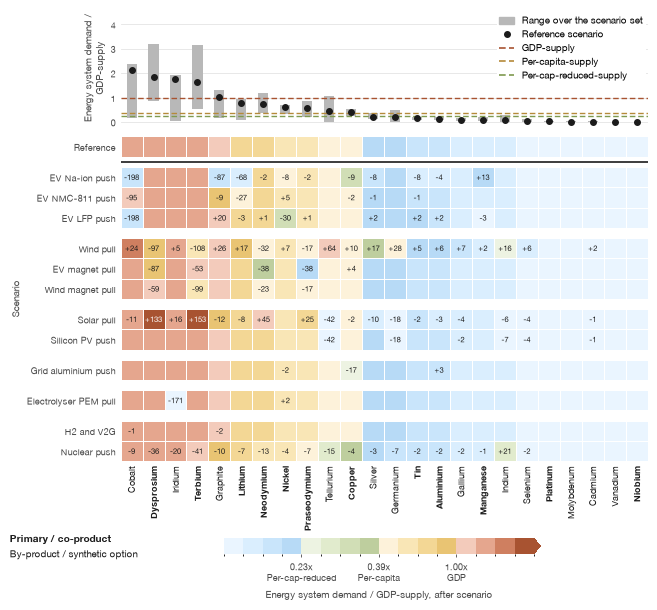

In [8]:
scenario_effects = pd.read_csv(paths["scenario_effects"])
matrix_style = scenario_effects_style["matrix"]

# Scenarios are the rows: a row is one decision's whole effect, read left to right,
# which is what the figure is for. They keep the config's order, with the
# reference above them and ruled off from them — it is not a decision but the state
# every other row is measured from.
alternatives = [s for s in scenarios if s != reference]

# Blocked by the group each scenario claims — which metals it interrogates — and set
# apart by blank space rather than named: the columns already carry the metals a
# name would repeat.
scenario_blocks = plotting.grouped_members(
    alternatives, {s: info["group"] for s, info in scenario_info.items()}, scenario_groups
)
row_order = [
    reference, *(s for members in scenario_blocks.values() for s in members)
]
row_blocks, cursor = [0], 1
for members in scenario_blocks.values():
    row_blocks.append(cursor)
    cursor += len(members)

effects_here = scenario_effects[
    scenario_effects[ScenarioEffect.allocation_method] == reference_method
]
# A hole in the grid would draw as a blank cell, which reads like "no effect".
carried = set(
    zip(effects_here[ScenarioEffect.scenario], effects_here[ScenarioEffect.metal])
)
wanted = {(scenario, metal) for scenario in alternatives for metal in metals}
if carried != wanted:
    raise ValueError(
        "scenario_effects.csv and the figures disagree on the (scenario, metal) grid — "
        f"missing {sorted(wanted - carried)}, unexpected {sorted(carried - wanted)}"
    )

def metal_order(base_column):
    """The metals worst-off first on `base_column`, or in end-use order."""
    if row_sort == "shortfall":
        return list(placed[base_column].sort_values(ascending=False).index)
    elif row_sort == "group":
        return metals
    else:
        raise ValueError(
            f"compare.floor.sort_by is {row_sort!r}; expected 'shortfall' or 'group'"
        )


def scenario_frame(column, order):
    """One value per (scenario, metal), in the figure's row order and `order`."""
    return effects_here.pivot(
        index=str(ScenarioEffect.scenario),
        columns=str(ScenarioEffect.metal),
        values=str(column),
    ).reindex(index=row_order, columns=order)


def scenario_state(column, base_column):
    """Where each scenario leaves each metal on `column`, the reference row read off
    metal_positions.csv's `base_column`. Each matrix sorts on its own reference, as
    other-sector demand reorders the metals almost completely."""
    order = metal_order(base_column)
    state = scenario_frame(column, order)
    state.loc[reference] = placed[base_column].reindex(order)
    return state


# The number on a cell is how far the scenario moved the metal, which the reference
# row — being the origin — has none of. Other-sector demand is a constant per
# metal, so it cancels out of every move and both matrices print the same ones.
moves = scenario_frame(ScenarioEffect.delta_supply_points, metals)

# `methods` is strictest first, so the parities ascend with it. A parity is its
# principle's supply line, so it is drawn in that line's style on every figure.
# The key names them top down, in the order the lines stand in the strip.
parity_style = {
    m: {
        "color": allocation_style[m]["supply_color"],
        "linestyle": allocation_style[m]["supply_linestyle"],
    }
    for m in methods
}
parity_lines = {ratio_parity[m]: parity_style[m] for m in methods}
parity_key = {f"{method_short[m]}-supply": parity_style[m] for m in reversed(methods)}

cmap, norm = plotting.band_scale([ratio_parity[m] for m in methods], matrix_style)


def scenario_matrix(state, strip, quantity, name):
    """The scenario x metal matrix over its strip, written out as `name`.

    `state` is the colour, `strip` what the scenarios act on, both as `quantity`
    over the reference principle's supply: `low` to `high` the scenario span,
    `reference` inside it, and `floor` the other-sector demand no scenario reaches,
    drawn and named only where given.
    """
    supply = f"{method_short[reference_method]}-supply"
    strip = strip.reindex(state.columns)
    if strip["high"].max() > matrix_style["cap"]:
        raise ValueError(
            f"compare.scenario_effects.matrix.cap is {matrix_style['cap']}, below the worst "
            f"scenario's demand for {strip['high'].idxmax()} "
            f"({strip['high'].max():.2f}x), whose bar the strip would clip"
        )

    fig, (strip_axes, ax) = plotting.matrix_strip_figure(
        state, matrix_style, row_blocks=row_blocks
    )
    # No title: the caption is written where the figure is published. The column
    # names carry the supply-side character, as Fig. 1's do — a metal whose output
    # is a fraction of another's is a different kind of problem from one whose is
    # not, and no cell of the matrix says so.
    mesh, headers = plotting.heat_matrix(
        ax,
        state.rename(index=scenario_nice),
        cmap,
        norm,
        matrix_style,
        style,
        title=None,
        row_rules=[1],
        row_blocks=row_blocks,
        numbers=moves[state.columns],
        column_label_styles=metal_label_style,
        ylabel=matrix_style["ylabel"],
    )
    plotting.level_strip(
        strip_axes, strip, parity_lines, matrix_style, style,
        ylabel=f"{quantity} /\n{supply}",
    )
    # The strip's marks are named in the strip, the column names under the matrix.
    plotting.strip_key(
        strip_axes,
        matrix_style,
        style,
        reference=f"{scenario_nice[reference]} scenario",
        parities=parity_key,
        floor="Other-sector floor" if "floor" in strip else None,
    )

    colours = plotting.band_colorbar(
        fig,
        mesh,
        [strip_axes, ax],
        {method_short[m]: ratio_parity[m] for m in methods},
        style,
        label=f"{quantity} / {supply}, after scenario",
        # Under the panel, not beside it: stood up, the bar and its tick names cost
        # 1.3 in of a figure that has to be printed at the width of a portrait page.
        orientation="horizontal",
    )
    # In the corner under the row names, level with the colour bar.
    legend = plotting.corner_key(
        fig, colours.ax,
        {label: class_label_style[name] for label, name in class_key.items()},
    )

    plotting.save_figure(
        fig, figures_dir, name, style, (colours.ax, legend, *headers)
    )


energy_strip = pd.DataFrame(
    {
        "low": placed[MetalPosition.energy_over_supply_reduced],
        "high": placed[MetalPosition.energy_over_supply_raised],
        "reference": placed[MetalPosition.energy_over_supply_base],
    }
)
scenario_matrix(
    scenario_state(ScenarioEffect.energy_over_supply, MetalPosition.energy_over_supply_base),
    energy_strip,
    "Energy system demand",
    "scenario_effects_matrix",
)

parity = ratio_parity[reference_method]
material = moves.abs() >= matrix_style["annotate_above"]
idle = [s for s in alternatives if not material.loc[s].any()]
print(f"\nscenarios that move nothing by {matrix_style['annotate_above']:.0f} points or "
      f"more, so draw an empty row: {', '.join(scenario_nice[s] for s in idle) or 'none'}")

short = energy_strip[energy_strip["reference"] > parity]
reachable = short[short["low"] <= parity]
print(f"short at {scenario_nice[reference]} on energy-system demand alone: "
      f"{len(short)} of {len(energy_strip)} metals; a scenario takes "
      f"{', '.join(reachable.index) or 'none'} under parity")
for name, spec in metal_type_classes.items():
    named = ", ".join(m for m in short.index if metal_class[m] == name)
    print(f"  of those short metals, {spec['nice_name']}: {named or 'none'}")

short at Reference on total demand: 11 of 24 metals; a scenario takes Graphite, Copper under parity, while Iridium, Silver, Germanium, Platinum, Cadmium are past it on other-sector demand alone


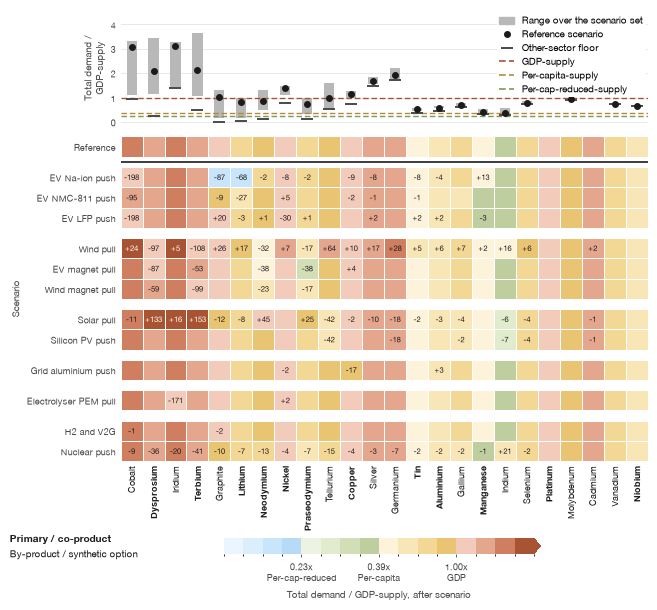

In [9]:
total_strip = pd.DataFrame(
    {
        "low": placed[MetalPosition.total_over_supply_reduced],
        "high": placed[MetalPosition.total_over_supply_raised],
        "reference": placed[MetalPosition.total_over_supply_base],
        "floor": placed[MetalPosition.non_energy_over_supply],
    }
)
scenario_matrix(
    scenario_state(ScenarioEffect.total_over_supply, MetalPosition.total_over_supply_base),
    total_strip,
    "Total demand",
    "scenario_effects_matrix_total_demand",
)

short = total_strip[total_strip["reference"] > parity]
reachable = short[short["low"] <= parity]
locked = short[short["floor"] > parity]
print(f"short at {scenario_nice[reference]} on total demand: {len(short)} of "
      f"{len(total_strip)} metals; a scenario takes {', '.join(reachable.index) or 'none'} "
      f"under parity, while {', '.join(locked.index) or 'none'} are past it on "
      "other-sector demand alone")

## Fig. 3

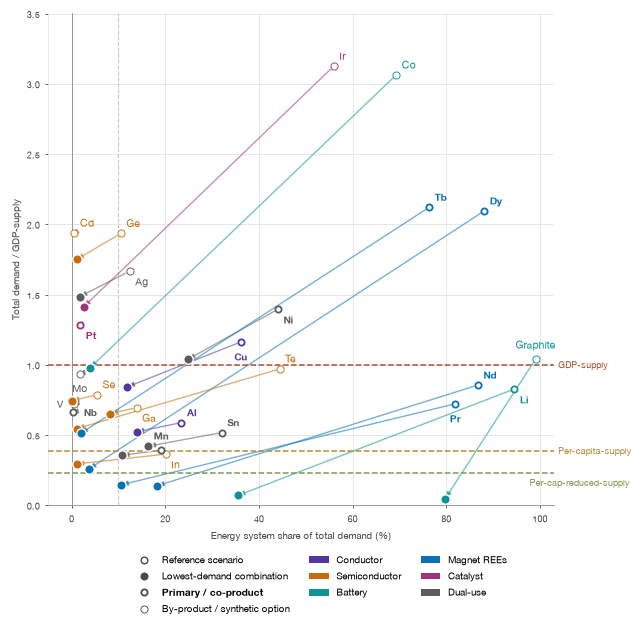

In [10]:
frame = pd.DataFrame(
    {
        "x": placed[MetalPosition.energy_share_of_demand_base_percent],
        "y": placed[MetalPosition.total_over_supply_base],
        "x_to": placed[MetalPosition.energy_share_of_demand_combined_percent],
        "y_to": placed[MetalPosition.total_over_supply_combined],
    }
)
levels = parity_levels(MetalPosition.parity_level_ratio)

# Colour is the end-use group: what the metal is wanted for, in the hue of the
# Fig. 1 technology family that group serves.
metal_group_color = {m: group_color[mineral_info.loc[m, MineralInfo.group]] for m in metals}

# The supply-side class is in the metal's name, as on Figs. 1 and 2, and in its
# marker's shape; the fill says which end of the trace a point is.
trace = positions_style["trace"]
metal_marker = {m: metal_type_classes[metal_class[m]] for m in metals}

panel = positions_style["panel"]
fig, ax = plt.subplots(figsize=(panel["width"], panel["height"]), layout="constrained")
# No title: the caption is written where the figure is published.
plotting.style_scatter(
    ax, style,
    title=None,
    xlabel="Energy system share of total demand (%)",
    ylabel=f"Total demand / {method_short[reference_method]}-supply",
)

# Limits before anything is drawn: traced_points sizes its "too short to mark"
# threshold off the x range. The panel runs wider than the data on the left so
# that label_points can put a crowded name to the *left* of its marker -- ten
# metals sit under x = 10, and without the margin every one of those labels is
# forced right, into its neighbour. The axis is still ticked over the 0-100 a
# share actually spans.
ax.set_xlim(*positions_style["x_limits"])
ax.set_xticks(range(0, 101, 20))
# ...so the axis itself is drawn where a share starts rather than where the
# packing margin does; the left limit stays as a quiet edge in the grid's hue.
plotting.stand_y_axis_at(ax, style, 0)
share_rule = positions_style["share_rule"]
ax.axvline(
    share_rule["percent"], color=share_rule["color"], linewidth=share_rule["linewidth"],
    linestyle=share_rule["linestyle"], zorder=0.6,
)
high = max(frame[["y", "y_to"]].max().max(), max(levels.values()))
ax.set_ylim(0, high * 1.12)

line_names = plotting.reference_lines(
    ax, levels, allocation_style, "supply_color", "supply_linestyle",
    labels={m: f"{method_short[m]}-supply" for m in methods},
    tuck_longest=positions_style["tuck_longest_line_name"],
)
# No quadrant crosshair: the parity lines already divide the panel, and a
# crosshair would divide it a second, competing way.
plotting.traced_points(
    ax, frame, metal_group_color, {m: spec["marker"] for m, spec in metal_marker.items()},
    trace, style["ink"], filled_end="reduced",
    size_scales={m: spec["marker_scale"] for m, spec in metal_marker.items()},
    outline_scales={m: spec["outline_scale"] for m, spec in metal_marker.items()},
)
# traced: the arrows and the ends they run to are drawn, so a name has to
# dodge them as well as the markers it starts from; rules: the parity lines
# cross the whole panel, and one of them strikes through whatever it meets.
plotting.label_points(
    ax, frame, position_name, metal_group_color, positions_style["label"],
    label_styles=metal_label_emphasis, traced=True, rules=list(levels.values()),
    pinned=positions_style["label"]["pinned"],
)

# A column of the marks -- which end of a trace a point is, then the two classes,
# drawn open so the primary's heavier ring shows -- then two of end-use colours,
# in mineral_info.csv order (Fig. 1's bar order).
group_handles = plotting.patch_handles(list(grouped), group_color, group_nice)
group_rows = -(-len(group_handles) // 2)
mark_handles = [
    plotting.trace_handle(f"{scenario_nice[reference]} scenario", trace["marker"], False, trace, style["ink"]),
    plotting.trace_handle("Lowest-demand combination", trace["marker"], True, trace, style["ink"]),
    *[
        plotting.trace_handle(
            spec["nice_name"], spec["marker"], False, trace, style["ink"],
            size_scale=spec["marker_scale"], outline_scale=spec["outline_scale"],
        )
        for spec in metal_type_classes.values()
    ],
]
legend = fig.legend(
    handles=plotting.column_handles(
        [mark_handles, group_handles[:group_rows], group_handles[group_rows:]]
    ),
    frameon=False,
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.0),
)
for text in legend.get_texts():
    if text.get_text() in class_key:
        text.set(**class_emphasis[class_key[text.get_text()]])

plotting.save_figure(
    fig, figures_dir, "metal_positions_total_demand_by_group", style,
    (legend, *line_names),
)